Deliverable 1

Ida Sofie Ramsli & Emilie Marthinsen Kålås

Data retrieved from frost.met.no!


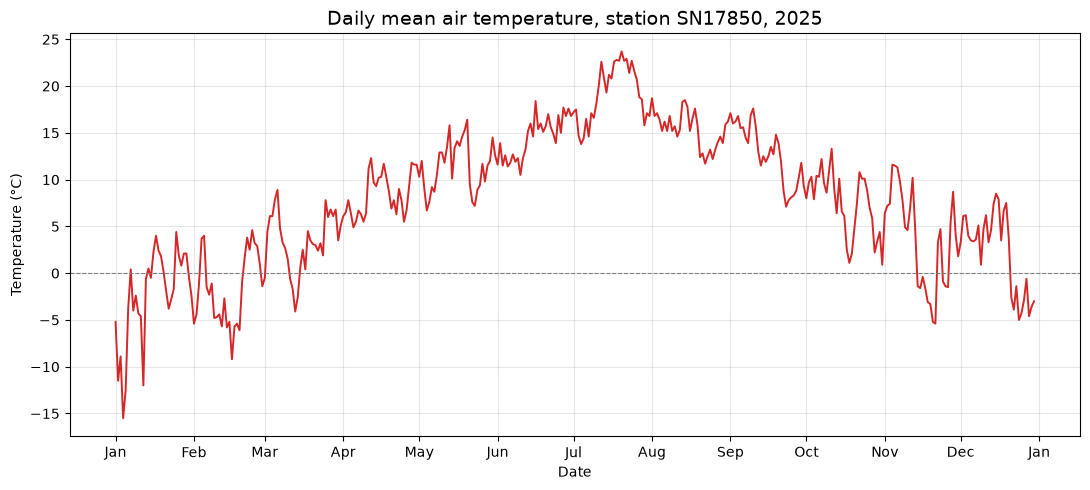


Summary of daily mean air temperature, 2025
Statistic  Temperature (°C)
     Mean               7.9
   Median               8.4
      Min             -15.5
      Max              23.7


In [ ]:


from pathlib import Path

import requests
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates


# --- 1. Request the data from Frost ---------------------------------------

client_id_file = Path.home() / "frost_client_id.txt"
client_id = client_id_file.read_text().strip()

endpoint = "https://frost.met.no/observations/v0.jsonld"
parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "2025-01-01/2025-12-31",
}

r = requests.get(endpoint, parameters, auth=(client_id, ""))
json_data = r.json()

if r.status_code != 200:
    error = json_data.get("error", {})
    raise SystemExit(
        f"Request failed ({r.status_code}): {error.get('message')} - {error.get('reason')}"
    )

print("Data retrieved from frost.met.no!")

# --- 2. Convert to a DataFrame --------------------------------------------
rows = []
for item in json_data["data"]:
    obs = item["observations"][0]  # one daily mean per reference time
    rows.append(
        {
            "time": pd.to_datetime(item["referenceTime"]).tz_localize(None),
            "temperature": obs["value"],
        }
    )

df = pd.DataFrame(rows).sort_values("time").reset_index(drop=True)

# --- 3. Plot ---------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(df["time"], df["temperature"], color="tab:red", linewidth=1.4)
ax.axhline(0, color="gray", linestyle="--", linewidth=0.8)

ax.set_title("Daily mean air temperature, station SN17850, 2025", fontsize=14)
ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

# --- 4. Summary table ------------------------------------------------------
temp = df["temperature"]
summary = pd.DataFrame(
    {
        "Statistic": ["Mean", "Median", "Min", "Max"],
        "Temperature (°C)": [temp.mean(), temp.median(), temp.min(), temp.max()],
    }
)

print("\nSummary of daily mean air temperature, 2025")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.1f}"))